# Ornstein-Uhlenbeck Process for Pairs Trading Strategy

### 3.1 Overview
- The Ornstein-Uhlenbeck Process for Pairs Trading Strategy models the spread between - ALCH/USDT and BTC/USDT as an Ornstein-Uhlenbeck process, trading when the spread    - deviates from equi-librium. A bullish signal triggers a long position in ALCH/USDT  - and a short in BTC/USDT when the spread is below equilibrium. A bearish signal      - reverses the positions. ATR sets TP/SL levels, optimized for 1-minute candles with  - 5x leverage.

### 3.2.1 Signal Generation

- • Bullish: Spread + < H - o, triggers long ALCH/USDT, short BTC/USDT.
- • Bearish: Spread + > + 0, triggers short ALCH/USDT, long BTC/USDT.
- • Example: Spread = -0.015, = 0, o = 0.01. Long ALCH/USDT, short BTC/USDT.

### 3.4.1 Model Type

- Ornstein-Uhlenbeck process for spread modeling, implemented with 'statsmodels and   - numerical estimation.

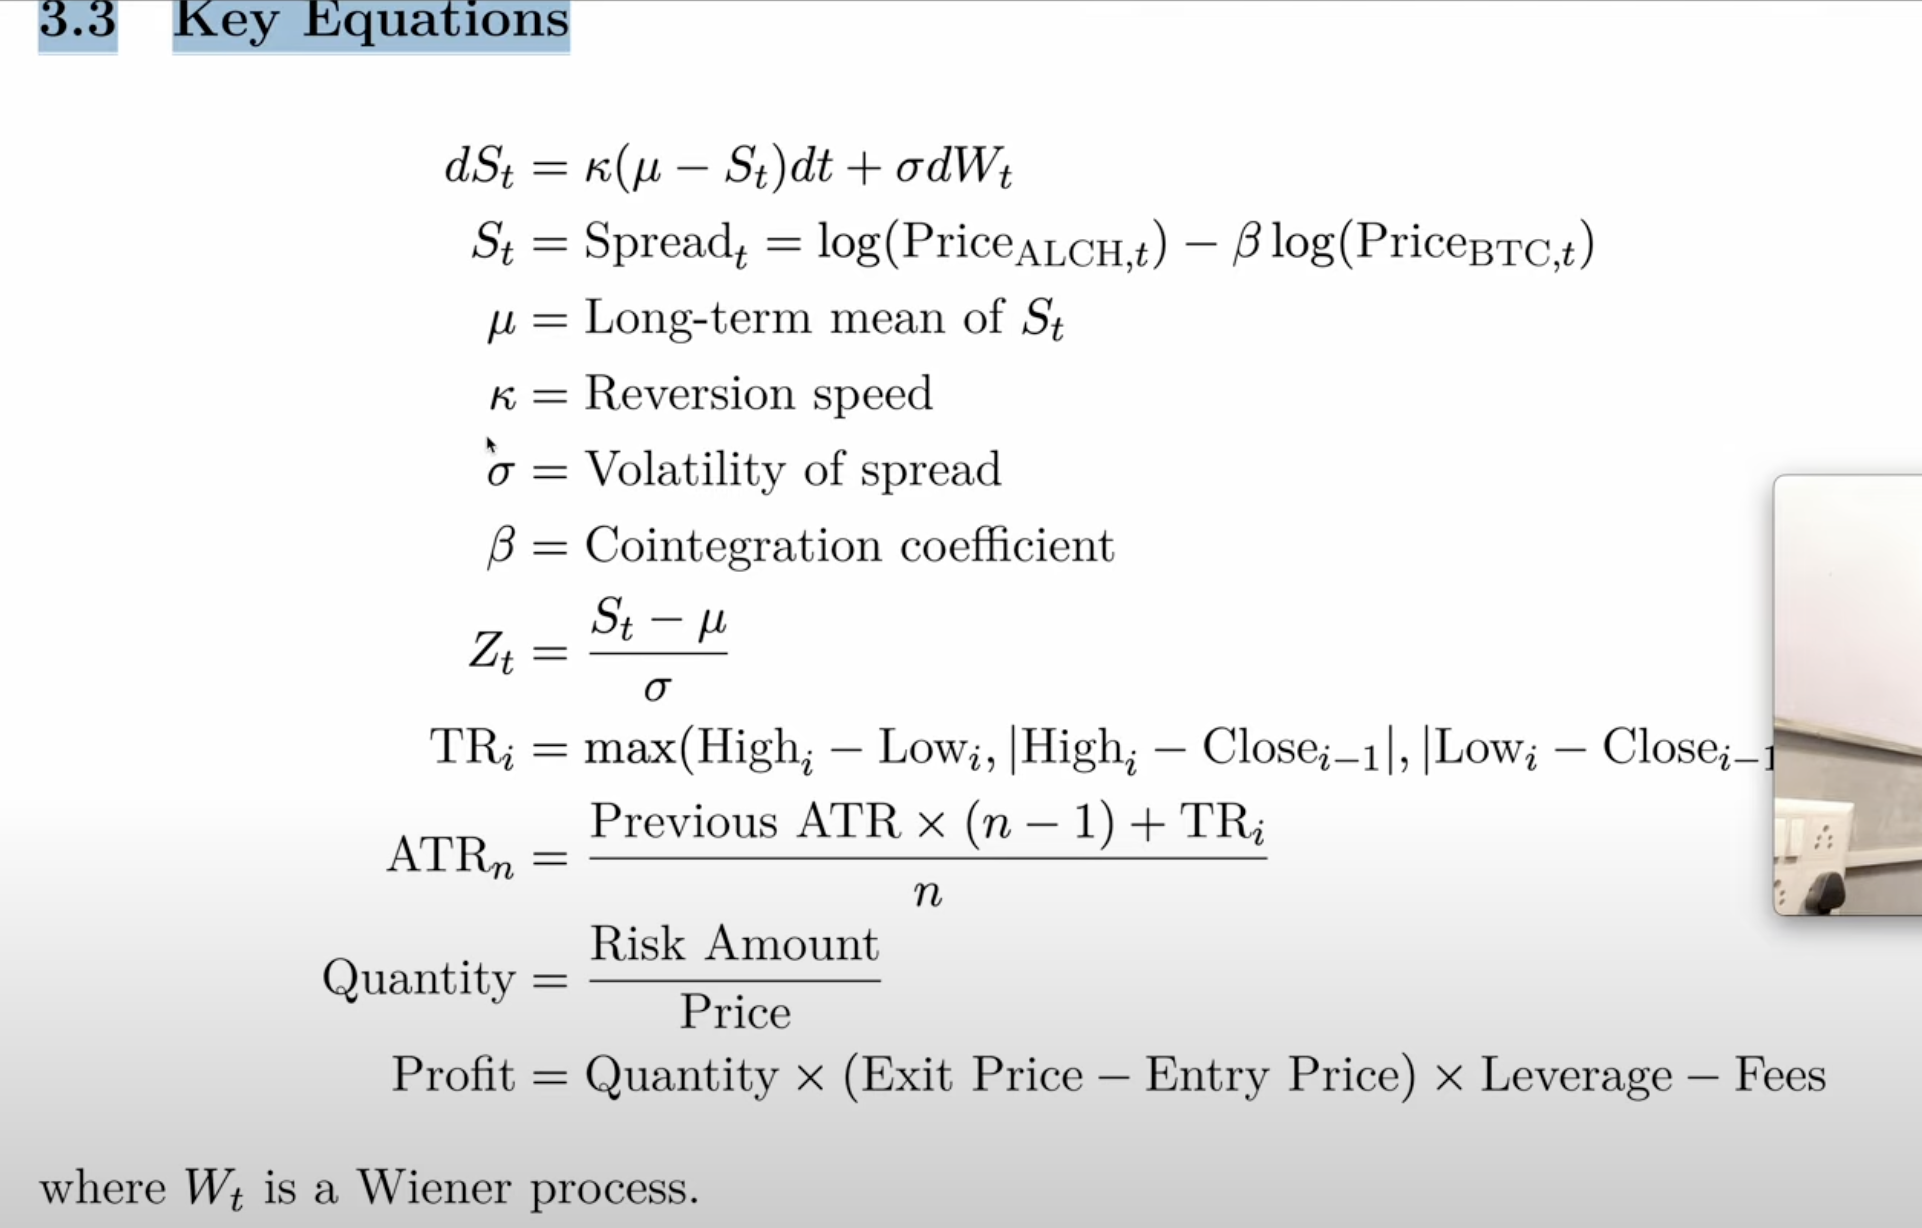

In [23]:
import ccxt.async_support as ccxt
import pandas as pd
import numpy as np 
import asyncio
import nest_asyncio
import logging
import statsmodels.api as sm

logging.basicConfig(level = logging.INFO , format = '%(asctime)s -  %(message)s')
logger = logging.getLogger(__name__)
nest_asyncio.apply()

In [3]:
SYMBOL1 = 'ALCH/USDT'
SYMBOL2 = 'BTC/USDT'
TIMEFRAME = '1m'
RISK_AMOUNT = 10.0
LEVERAGE = 5
LOOKBACK = 500
Z_THRESHOLD = 2.0
ATR_PERIOD = 14
TP_MULTIPLIER = 2.0
SL_MULTIPLIER = 1.0
FEE_RATE = 0.0002
MAX_POSITIONS = 2
CHECK_INTERVAL = 60

open_positions = []

In [4]:
async def fetch_data(exchange , symbol :str  , timeframe : str , limit : int = 100) -> pd.DataFrame:
    try:
        ohlcv = await exchange.fetch_ohlcv(symbol , timeframe , limit = limit)
        df = pd.DataFrame(ohlcv , columns = ['timestamp' , 'open' , 'high','low','close','volume'])
        df['timestamp'] = pd.to_datetime(df['timestamp'] , unit = 'ms')
        return df
    except Exception as e:
        logger.error(f"Error Fetching data: {str(e)}")
        return pd.DataFrame

In [5]:
def estimate_ou_params(spread: pd.Series , dt: float = 1/60/24) -> tuple:
    try:
        spread_diff = spread.diff().dropna()
        spread_lagged = spread.shift(1).dropna()
        spread_diff = spread_diff.iloc[1:]
        spread_lagged = spread_lagged.iloc[1:]
        X = sm.add_constant(spread_lagged)
        model = sm.OLS(spread_diff , X).fit()
        kappa = -model.params[-1] / dt
        mu  = model.params[0] / (kappa * dt)
        sigma = np.std(model.resid) / np.sqrt(dt)
        return kappa, mu , sigma
    except Exception as e:
        logger.error(f"Error estimating OU params: {str(e)}")
        return None , None , None 

In [6]:
def calculate_indicators(df1 : pd.DataFrame , df2 : pd.DataFrame) -> pd.DataFrame:
    try:
        df = pd.DataFrame({'timestamp': df1['timestamp'] , 'alch': df1['close'] , 'btc' : df2['close']})
        df['log_alch'] = np.log(df['alch'])
        df['log_btc'] = np.log(df['btc'])
        X = sm.add_constant(df['log_btc'])
        model = sm.OLS(df['log_alch'] , X).fit()
        beta = model.params[1]
        df['spread'] = df['log_alch'] - beta  * df['log_btc']
        kappa , mu , sigma = estimate_ou_params(df['spread'])
        df['mu'] = mu
        df['sigma'] = sigma
        df['z_score'] = (df['spread'] - mu) / sigma
        df['tr'] = pd.concat([df1['high'] - df1['low'] , 
                            (df2['high'] - df1['close'].shift()).abs(),
                             (df1['low'] - df1['close'].shift()).abs()],
                            axis = 1).max(axis = 1)
        df['atr'] = df['tr'].rolling(ATR_PERIOD).mean()
    except Exception as e:
        logger.error(f"Error Calculating Indicators: {str(e)}")
        return df
        

In [7]:
def get_ou_signal(df : pd.DataFrame) -> str:
    try:
        z_score = df['z_score'].iloc[-1]
        if pd.isna(z_score):
            return 'neutral'
        if z_score < -Z_THRESHOLD:
            return "bullish"
        elif z_score > Z_THRESHOLD:
            return "bearish"
        return 'neutral'
    except Exception as e:
        logger.error(f"Error in signal generation: {str(e)}")
        return "Neutral"
        

In [8]:
async def manage_positions(exchange , current_price : float , symbol : str):
    global open_positions
    positions_to_remove = []
    try:
        for pos in open_positions:
            if pos['symbol'] != symbol:
                continue
            entry_price = pos['entry_price']
            qty = pos['quantity']
            side = pos['side']
            tp_price = pos['tp_price']
            sl_price = pos['sl_price']
            if side == 'long':
                if current_price >= tp_price:
                    logger.info(f"[check mark] Long TP hit at {current_price: .2f} , Profit:{(current_price - entry_price) * qty *  LEVERAGE:.2f}")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price <= sl_price:
                    logger.info(f"[cross mark] Long SL hit at {current_price: .2f} , Loss: {(entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
            else:
                if current_price <= tp_price:
                    logger.info(f"[check mark] Short TP hit at {current_price: .2f} , Profit: {( entry_price - current_price) * qty *  LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
                elif current_price >= sl_price:
                    logger.info(f"[cross mark] Short SL hit at {current_price: .2f} , Loss:{(current_price - entry_price) * qty  * LEVERAGE:.2f }")
                    await exchange.create_market_sell_order(symbol , qty)
                    positions_to_remove.append(pos)
        open_positions = [pos for pos in open_positions if pos not in positions_to_remove]
    except Exception as e:
        logger.error(f"Error managing the Positions: {str(e)}")

                
                    

In [9]:
async def place_order(exchange , signal: str , price : float , atr:float , symbol : str):
    try:
        if len(open_positions) >= MAX_POSITIONS:
            logger.info("Max positions reached, skipping new order")
            return
        qty = RISK_AMOUNT / price
        if signal == 'bullish':
            order = await exchange.create_market_buy_order(symbol ,qty )
            tp_price = price + TP_MULTIPLIER * atr;
            sl_price = price - SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' : symbol , 
                'side' : 'long',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened long at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
            btc_qty = qty * price / (await exchange.fetch_ticker(SYMBOL2))['last']
            await exchange.create_market_sell_order(SYMBOL2 , btc_qty )
        elif signal == 'bearsih':
            order = await exchange.create_market_sell_order(symbol ,qty )
            tp_price = price - TP_MULTIPLIER * atr;
            sl_price = price + SL_MULTIPLIER * atr;
            open_positions.append({
                'symbol' : symbol , 
                'side' : 'short',
                'entry_price' : price,
                'quantity' : qty,
                'tp_price' : tp_price , 
                'sl_price' : sl_price
            })
            logger.info(f"[char increasing] Opened short at {price:. 2f} , Qty: {qty:.4f} , TP: {tp_price:. 2f} , SL: {sl_price:. 2f}")
            btc_qty = qty * price / (await exchange.fetch_ticker(SYMBOL2))['last']
            await exchange.create_market_buy_order(SYMBOL2 , btc_qty )
    except Exception as e:
        logger.error(f"Error placing order: {str(e)}")
            
            
            
            
    

In [10]:
async def main():
    try:
        exchange = ccxt.binance({
            'enableRateLimit': True,
            'apiKey': 'your_api_key',
            'secret': 'your-api_secret',
            'enabledLeverage' : True
        })
        await exchange.load_markets()
        await exchange.set_leverage(LEVERAGE , SYMBOL1)
        await exchange.set_leverage(LEVERAGE , SYMBOL2)
        while True:
            try:
                df1 = await fetch_data(exchange , SYMBOL1 , TIMEFRAME)
                df2 = await fetch_data(exchange , SYMBOL2 , TIMEFRAME)
                if df1.empty or df2.empty:
                    await asyncio.sleep(CHECK_INTERVAL)
                    continue
                df = calculate_indicators(df1 , df2)
                current_price = df['alch'].iloc[-1]
                atr = df['atr'].iloc[-1]
                signal = get_ou_signal(df)
                await manage_positions(exchange , current_price , SYMBOL1)
                if signal != 'neutral':
                    await place_order(exchange , signal , current_price , atr ,SYMBOL1)

                logger.info(f"Price: {current_price:.2f}, OU Z-Score: {df['z_score'].iloc[-1]:.2f}, Signal: {signal}")
                await asyncio.sleep(CHECK_INTERVAL)
            except Exception as e:
                logger.error(f"Error in main loop: {str(e)}")
                await asynchio.sleep(CHECK_INTERVAL)
    except Exception as e:
        logger.error(f"Error initialiszing exchange: {str(e)}")
    finally:
        await exchange.close()
                

In [11]:
if __name__ == '__main__':
    asyncio.get_event_loop().run_until_complete(main())
    

2025-06-18 19:26:14,495 -  Error initialiszing exchange: binance GET https://api.binance.com/sapi/v1/capital/config/getall?timestamp=1750254974480&recvWindow=10000&signature=7edd6841c09ef9b27d0033dad182063c244c6829e37d527cac03bf6fb8c6a662
